# Camera Calibration Evaluation

In [1]:
import json
from analysis.data_preprocessing import *
from analysis.camera_calibration import *
from segmentation.segmenter import *
from analysis.camera_calibration import * 
from segmentation.segmenter import *
from PIL import Image
import pandas as pd
import os
from tqdm.notebook import tqdm
import math



Welcome to CellposeSAM, cellpose v
cellpose version: 	4.0.4 
platform:       	linux 
python version: 	3.11.11 
torch version:  	2.7.0+cu126! The neural network component of
CPSAM is much larger than in previous versions and CPU excution is slow. 
We encourage users to use GPU/MPS if available. 




### Data and Experiment Setup

In [2]:
chip_region = 1
EXPERIMENT_CONFIG = {
    "chip_region": chip_region,
    "data_dir": "../../data/Raw/Chip2-NaCl 0-19_",           # str, Image directory
    "image_batch": f"290-4-0.75x-{chip_region}",                          # str, Specific image batch, e.g. 290-4-0.75x-3
    "zoom": 0.75,                                            # float, Camera zoom
    "cc": False,                                              # bool, Use camera calibration
    "ffc": False,                                             # bool, Use flatfield correction
    "clahe": False,                                          # bool, Use clahe (for segmentation only)
    "model": "SAM2",                                         # str, SAM2 or CellposeSAM
    "approx": False,                                          # bool, Use approximated masks
    "approx_method": "ellipse",                              # str, "circle" or "ellipse"
    "overlay_masks": False,                                  # bool, use masks from first image on all following images
    "individual_intensities": False,                         # bool, show individual intensity points on intensity plots and link to segmentation results
    "filter_config": {
        "circularity_threshold": 0.7,
        "border_thres": 2,
        "max_groups": 2 if chip_region == 2 else 3,
        "eps_area": 40, 
        "eps_coords_medium": 90,
        "eps_coords_small": 70,
        "eps_coords_small_exclude": 20,
        "rough_only": False,
        "debug": False
    },
    "calibrator_config": {
        "ref_radii": {
            "region1": 500, # use large wells
            "region2": 175, # use medium wells - why is 250 too large?
            "region3": 500 # use large wells
        },
        "schematic_path1": "../../data/Raw/Chip-schematic/chip_cleaned_1_10.jpg",
        "schematic_path2": "../../data/Raw/Chip-schematic/chip_cleaned_2_8.jpg",
        "schematic_path3": "../../data/Raw/Chip-schematic/chip_cleaned_3_10.jpg",
        "calculate_individual": True
    },
    "debug": True
}

# Collect the right images from the specified directory and group them in batches of increasing NaCl concentration
data = data_preprocessing(EXPERIMENT_CONFIG["data_dir"], EXPERIMENT_CONFIG["image_batch"])

# Isolate the specified batch as a list of dictionaries
data = data[EXPERIMENT_CONFIG["image_batch"] + ".jpg"]

print(json.dumps(data, indent=4))

[
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-0_-1.jpg",
        "nacl_percentage": 0.0
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-1,3_-1.jpg",
        "nacl_percentage": 1.3
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-2,6_-1.jpg",
        "nacl_percentage": 2.6
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-3,9_-1.jpg",
        "nacl_percentage": 3.9
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-5,2_-1.jpg",
        "nacl_percentage": 5.2
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-6,5_-1.jpg",
        "nacl_percentage": 6.5
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-10,4_-1.jpg",
        "nacl_percentage": 10.4
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-14,7_-1.jpg",
        "nacl_percentage": 14.7
    },
    {
      

### Object Setup

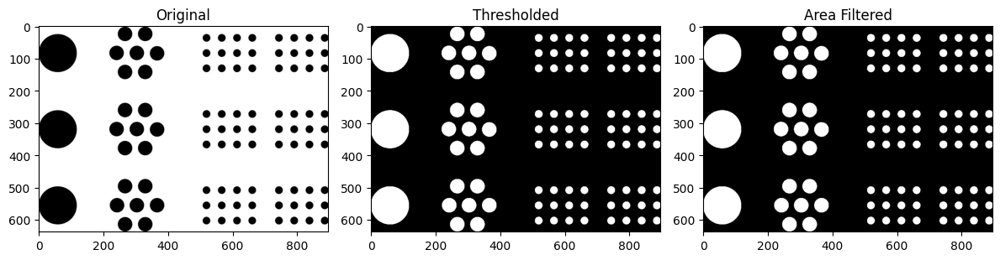

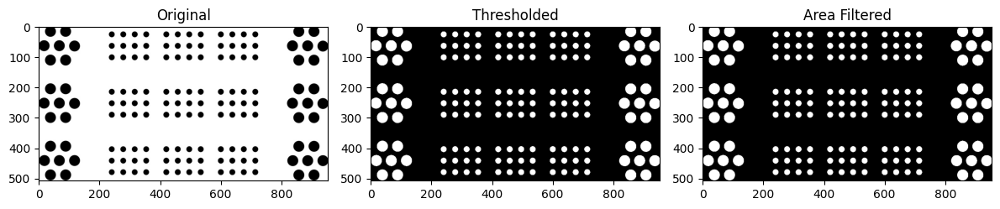

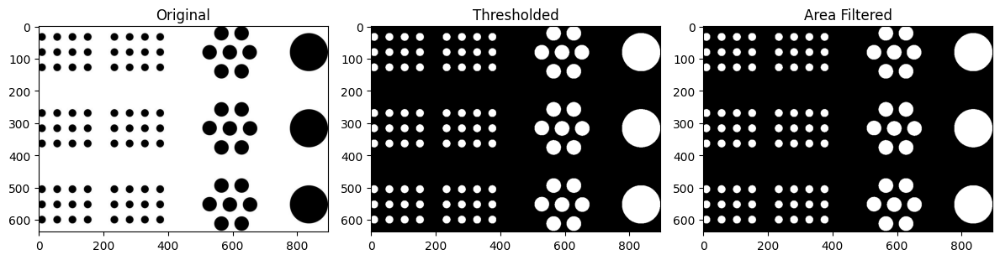

In [3]:
# Camera
camera = Camera(
    zoom=EXPERIMENT_CONFIG["zoom"],
    um_per_pixel=6.45
)

# Segmenter
finetuned_checkpoint = "../../models/Train81_200E_b+_like_sa1b/checkpoints/checkpoint.pt"
model_cfg_b_plus = "configs/sam2.1/sam2.1_hiera_b+.yaml"
sam2 = SAM2Wrapper(config=model_cfg_b_plus, checkpoint=finetuned_checkpoint, points_per_side=128)
cellposeSAM = CellposeSAMWrapper()
segmenter = Segmenter(model=sam2, filter_config=EXPERIMENT_CONFIG["filter_config"])

# Calibrator
setup_image_path = data[0]["file_path"]
setup_image = np.array(Image.open(setup_image_path).convert('L'))

schematic_path1 = EXPERIMENT_CONFIG["calibrator_config"]["schematic_path1"] 
schematic_raw1 = np.array(Image.open(schematic_path1).convert('L'))
schematic_mask1 = extract_schematic(image=schematic_raw1, debug=EXPERIMENT_CONFIG["debug"])
schematic_path2 = EXPERIMENT_CONFIG["calibrator_config"]["schematic_path2"] 
schematic_raw2 = np.array(Image.open(schematic_path2).convert('L'))
schematic_mask2 = extract_schematic(image=schematic_raw2, debug=EXPERIMENT_CONFIG["debug"])
schematic_path3 = EXPERIMENT_CONFIG["calibrator_config"]["schematic_path3"] 
schematic_raw3 = np.array(Image.open(schematic_path3).convert('L'))
schematic_mask3 = extract_schematic(image=schematic_raw3, debug=EXPERIMENT_CONFIG["debug"])
ref_images = {
    "region1": schematic_mask1,
    "region2": schematic_mask2,
    "region3": schematic_mask3,
}

calibrator = CameraCalibrator(
    setup_image=setup_image,
    camera=camera,
    segmenter=segmenter,
    ref_images=ref_images,
    ref_radii=EXPERIMENT_CONFIG["calibrator_config"]["ref_radii"],
    calculate_individual=EXPERIMENT_CONFIG["calibrator_config"]["calculate_individual"]
)

### Run Experiment

  0%|          | 0/9 [00:00<?, ?it/s]

==== Evaluating camera calibration for image 290-4-0,75x-0_-1. ====
[generate_masks] executed in 8.0382 seconds
[filter_masks] executed in 2.1339 seconds


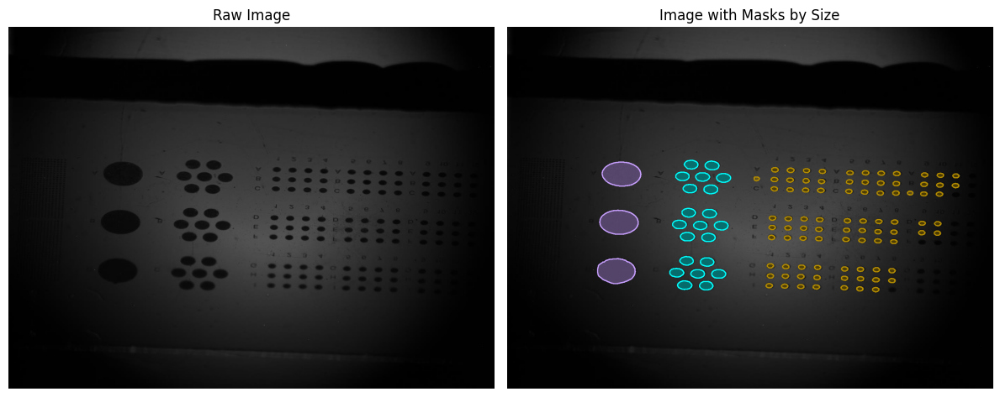

[visualize_masks_by_well_size] executed in 1.1624 seconds
[generate_masks] executed in 8.6101 seconds
[filter_masks] executed in 2.3440 seconds


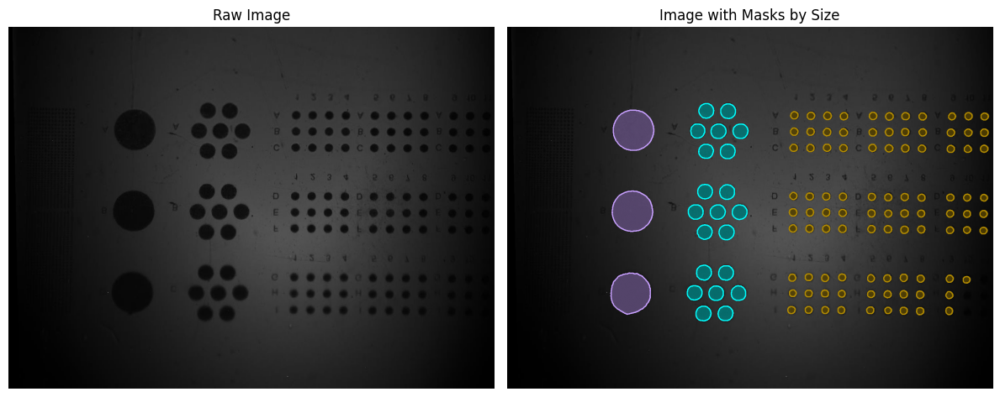

[visualize_masks_by_well_size] executed in 1.2282 seconds


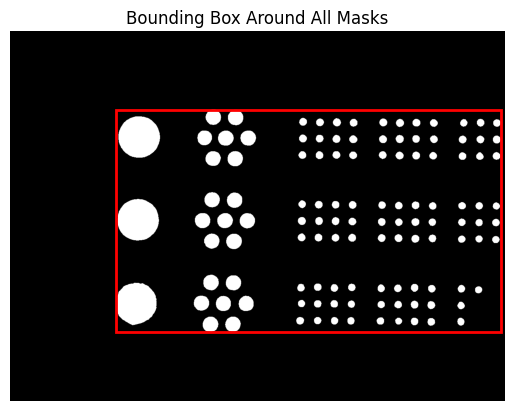

[generate_masks] executed in 8.0751 seconds
[filter_masks] executed in 2.3291 seconds
Translation: [14.87205006 47.17864493]
Scale: 1.0045262438681275
Rotation: -0.738205394817669°


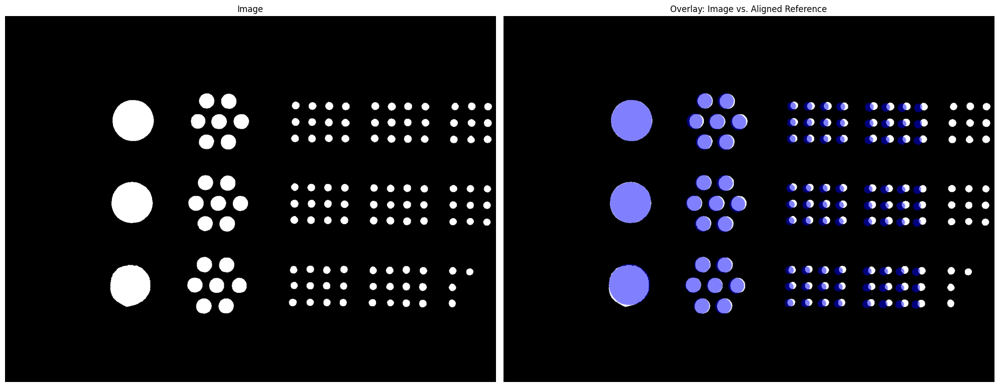

[_apply_imreg_dft] executed in 6.4363 seconds
[generate_masks] executed in 8.1991 seconds
[filter_masks] executed in 3.2050 seconds
Src: 96, Dst: 96


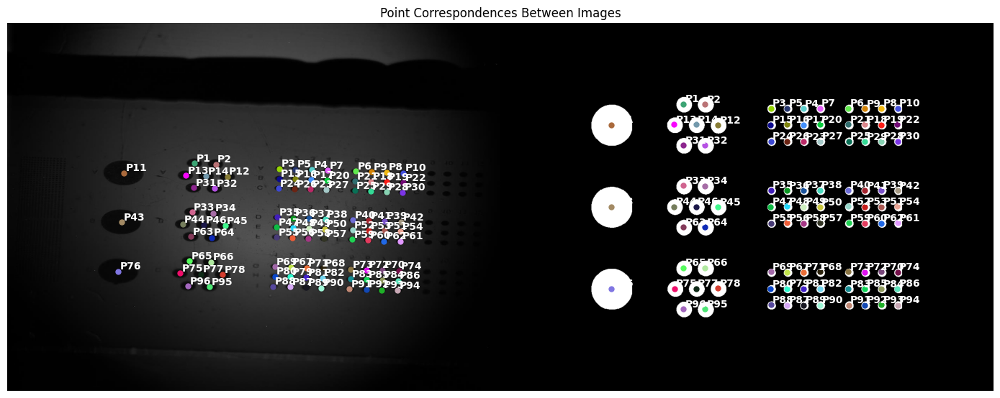

[calculate_homography] executed in 29.6448 seconds
[undistort] executed in 53.3859 seconds


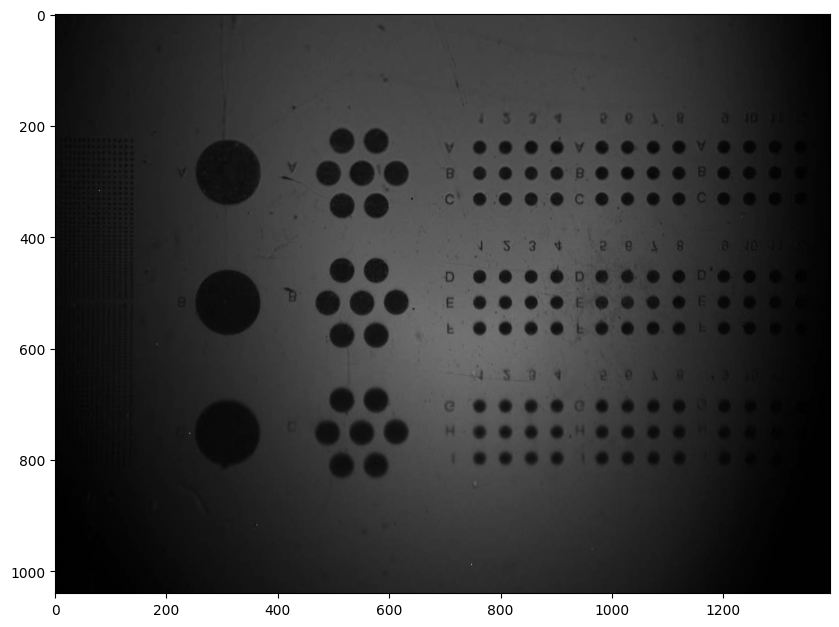

[generate_masks] executed in 8.6766 seconds
[filter_masks] executed in 2.2652 seconds
Translation: [14.87205006 47.17864493]
Scale: 1.0045262438681275
Rotation: -0.738205394817669°


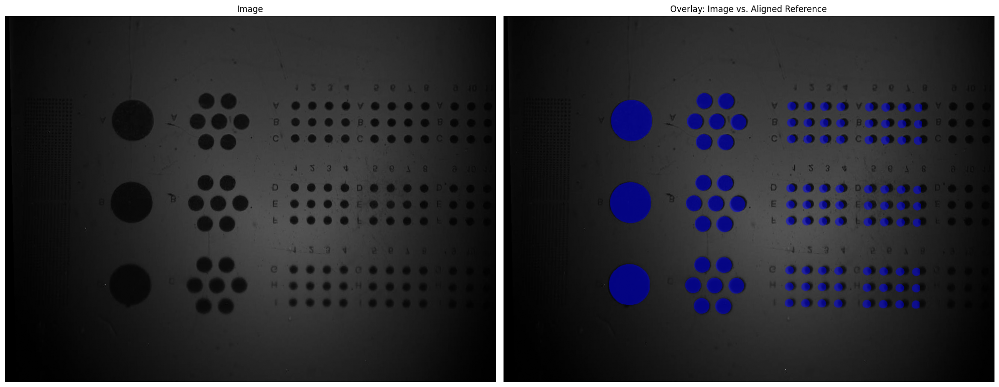

Average IoU all: 0.3671739662426978
Average IoU large: 0.9169163680585655
Average IoU medium: 0.8012269562303639
Average IoU small: 0.21766924408730076
[evaluate_camera_calibration] executed in 20.0864 seconds
[generate_masks] executed in 7.8990 seconds
[filter_masks] executed in 2.0764 seconds
Translation: [-1.6652459  -4.64887621]
Scale: 1.0012249539710947
Rotation: -0.02778425186315303°


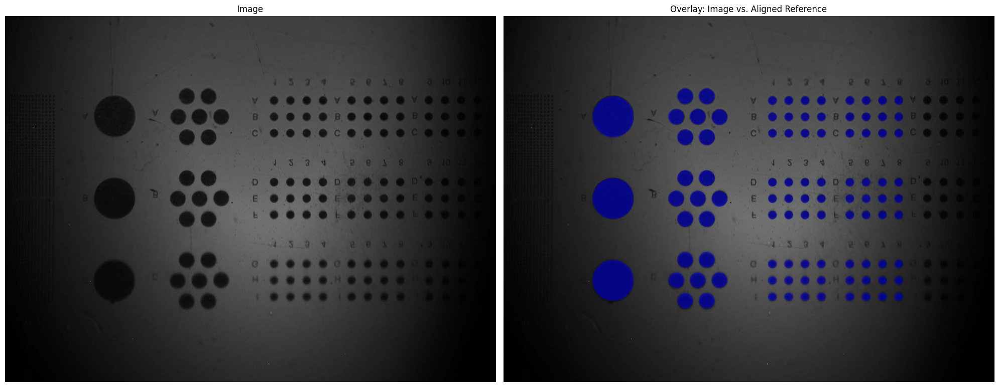

Average IoU all: 0.8420518423092561
Average IoU large: 0.9300539162966374
Average IoU medium: 0.8652021741812891
Average IoU small: 0.8316329090971052
[evaluate_camera_calibration] executed in 19.2750 seconds
==== Evaluating camera calibration for image 290-4-0,75x-1,3_-1. ====
[generate_masks] executed in 7.9521 seconds
[filter_masks] executed in 2.2291 seconds
Translation: [18.09219882 52.96746714]
Scale: 1.0045788507632212
Rotation: -0.6652331954414308°


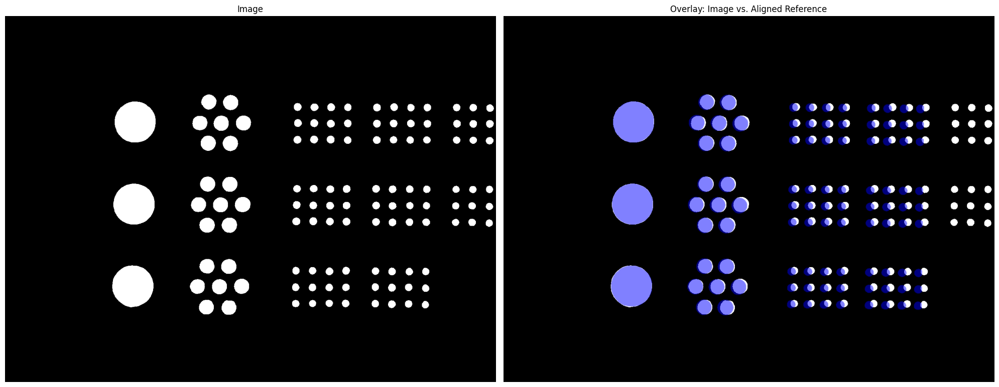

[_apply_imreg_dft] executed in 6.2139 seconds
[generate_masks] executed in 8.0677 seconds
[filter_masks] executed in 2.1682 seconds
Src: 96, Dst: 96


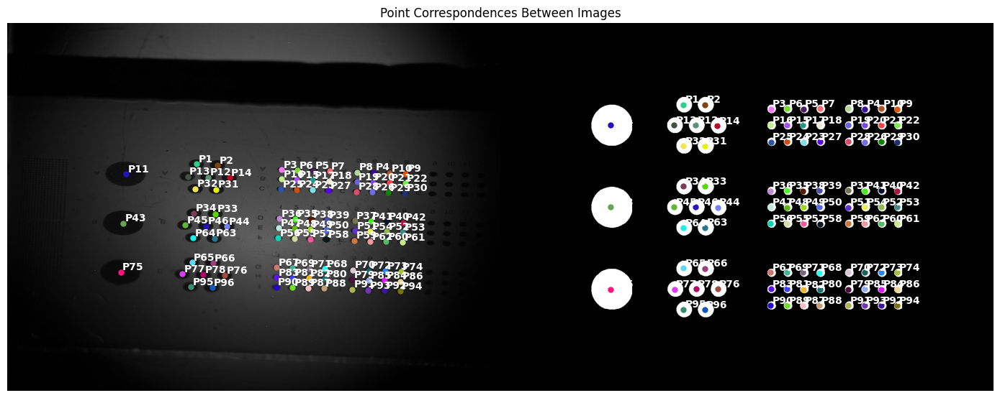

[calculate_homography] executed in 27.7097 seconds
[undistort] executed in 27.7179 seconds


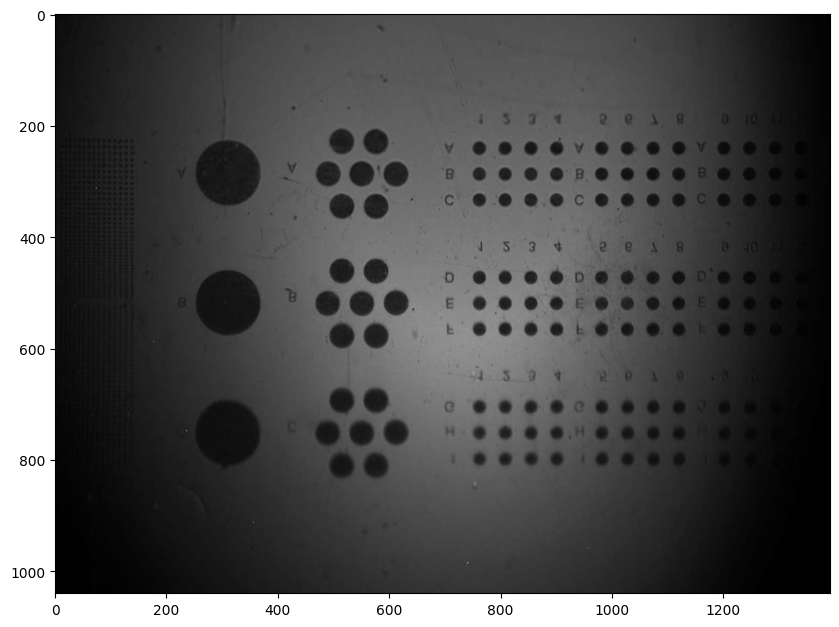

[generate_masks] executed in 7.9791 seconds
[filter_masks] executed in 2.1749 seconds
Translation: [18.09219882 52.96746714]
Scale: 1.0045788507632212
Rotation: -0.6652331954414308°


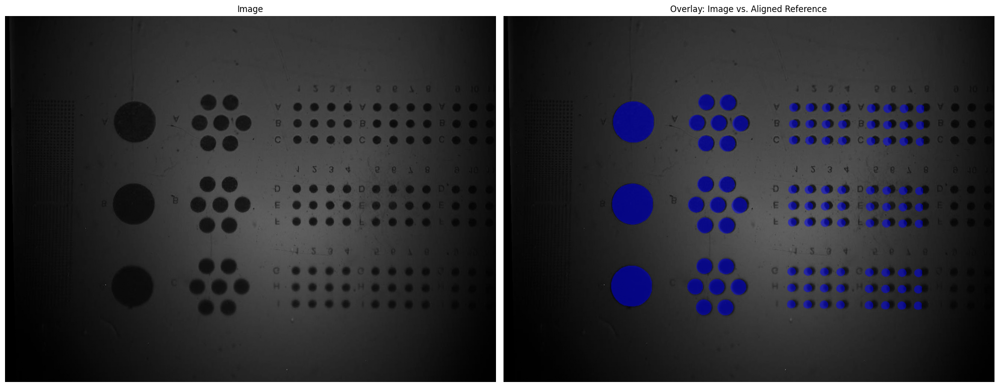

Average IoU all: 0.3170992325352429
Average IoU large: 0.923479716963241
Average IoU medium: 0.7424367477842279
Average IoU small: 0.1677766037364558
[evaluate_camera_calibration] executed in 19.3151 seconds
[generate_masks] executed in 7.9819 seconds
[filter_masks] executed in 1.8847 seconds
Translation: [-0.50993888 -4.45424205]
Scale: 1.0006053488767044
Rotation: -0.023851961362112206°


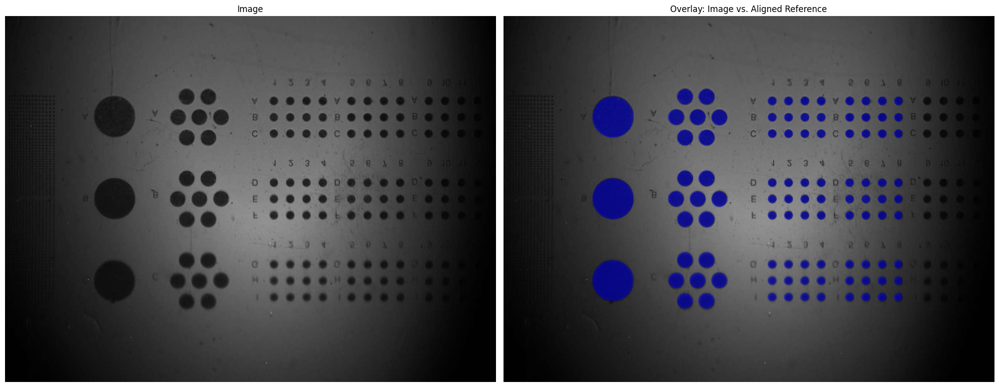

Average IoU all: 0.8357212748041967
Average IoU large: 0.9329319092019265
Average IoU medium: 0.8847951701603873
Average IoU small: 0.8173576122254022
[evaluate_camera_calibration] executed in 21.2066 seconds
==== Evaluating camera calibration for image 290-4-0,75x-2,6_-1. ====
[generate_masks] executed in 7.9814 seconds
[filter_masks] executed in 2.2311 seconds
Translation: [18.9668066  52.33460657]
Scale: 1.0052598175093022
Rotation: -0.6605894090971844°


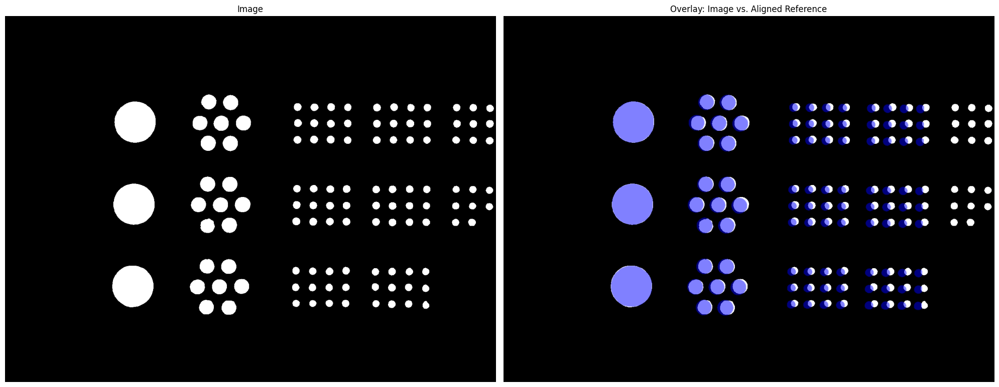

[_apply_imreg_dft] executed in 6.1816 seconds
[generate_masks] executed in 8.2094 seconds
[filter_masks] executed in 2.3162 seconds
Src: 96, Dst: 96


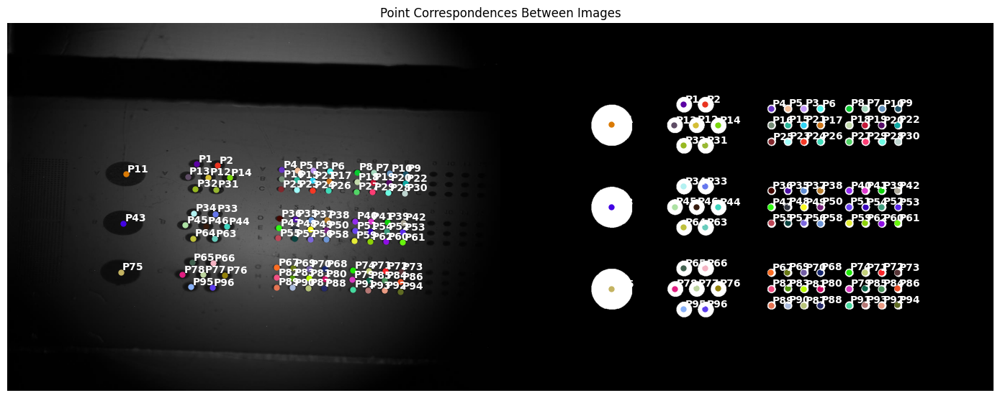

[calculate_homography] executed in 27.9861 seconds
[undistort] executed in 27.9944 seconds


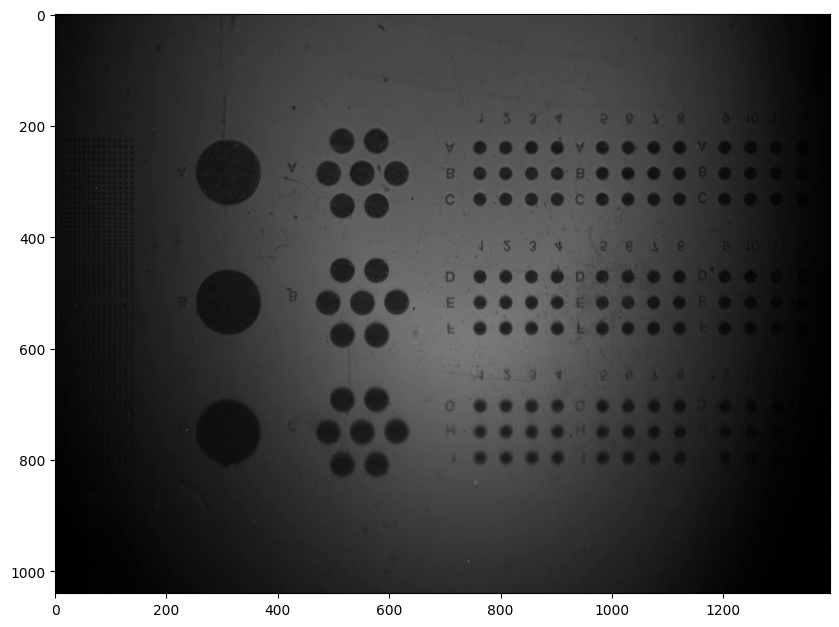

[generate_masks] executed in 7.9269 seconds
[filter_masks] executed in 2.3400 seconds
Translation: [18.9668066  52.33460657]
Scale: 1.0052598175093022
Rotation: -0.6605894090971844°


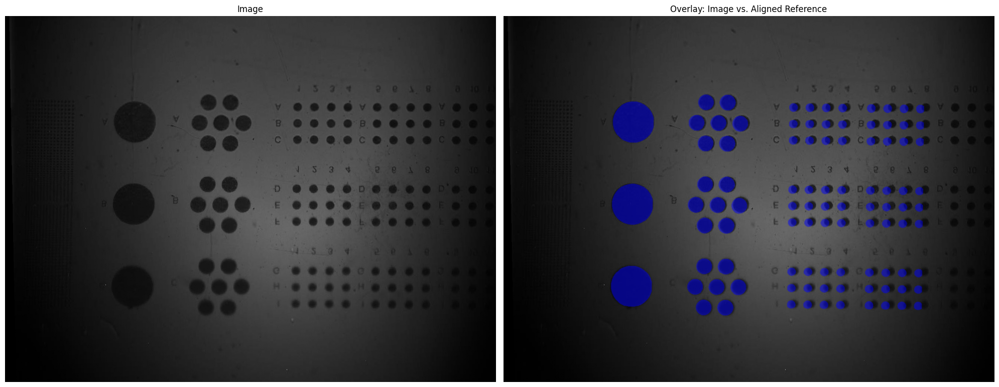

Average IoU all: 0.34392643756330854
Average IoU large: 0.9239846244104974
Average IoU medium: 0.7590570257941407
Average IoU small: 0.19663183314937843
[evaluate_camera_calibration] executed in 19.4685 seconds
[generate_masks] executed in 7.9156 seconds
[filter_masks] executed in 2.1615 seconds
Translation: [-1.67194405 -3.61113123]
Scale: 0.9999070161767967
Rotation: -0.006945881803630982°


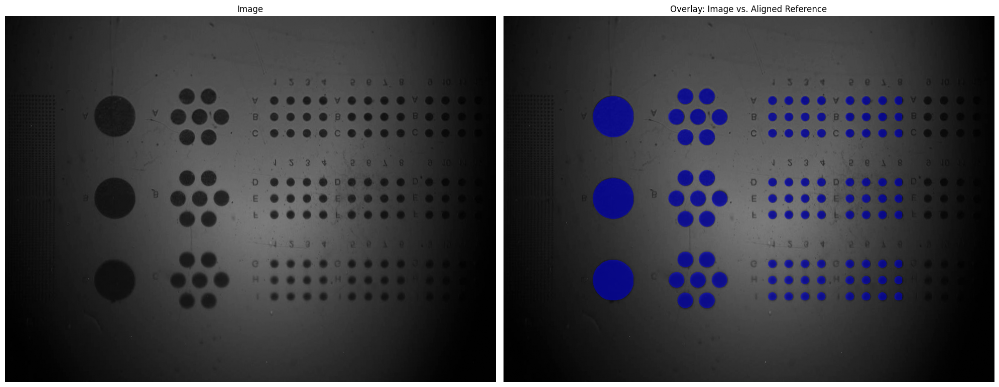

Average IoU all: 0.8339787022949583
Average IoU large: 0.9498178389396744
Average IoU medium: 0.90530489952507
Average IoU small: 0.8083485974093132
[evaluate_camera_calibration] executed in 19.7639 seconds
==== Evaluating camera calibration for image 290-4-0,75x-3,9_-1. ====
[generate_masks] executed in 8.5995 seconds
[filter_masks] executed in 3.5242 seconds
Translation: [20.30944823 53.15378214]
Scale: 1.005253050609981
Rotation: -0.6723637157259361°


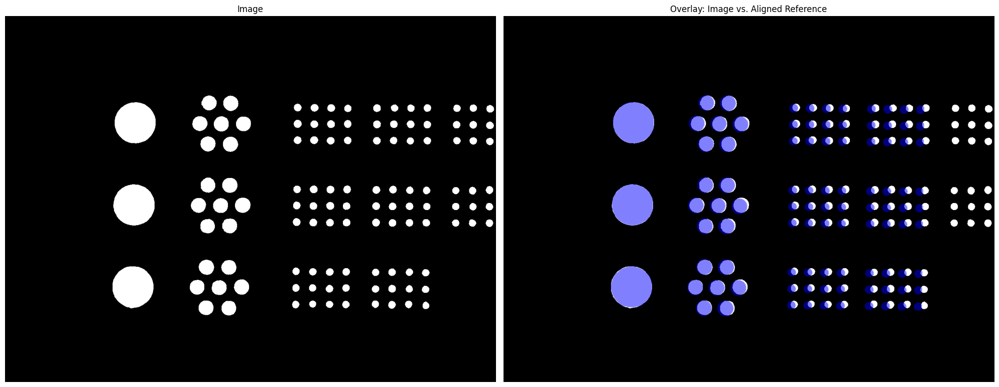

[_apply_imreg_dft] executed in 9.3917 seconds
[generate_masks] executed in 7.9352 seconds
[filter_masks] executed in 1.7751 seconds
Src: 96, Dst: 96


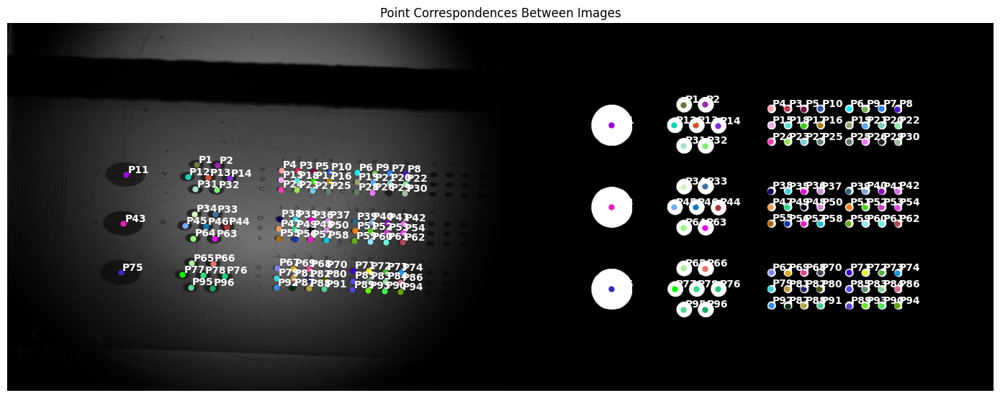

[calculate_homography] executed in 32.4448 seconds
[undistort] executed in 32.4531 seconds


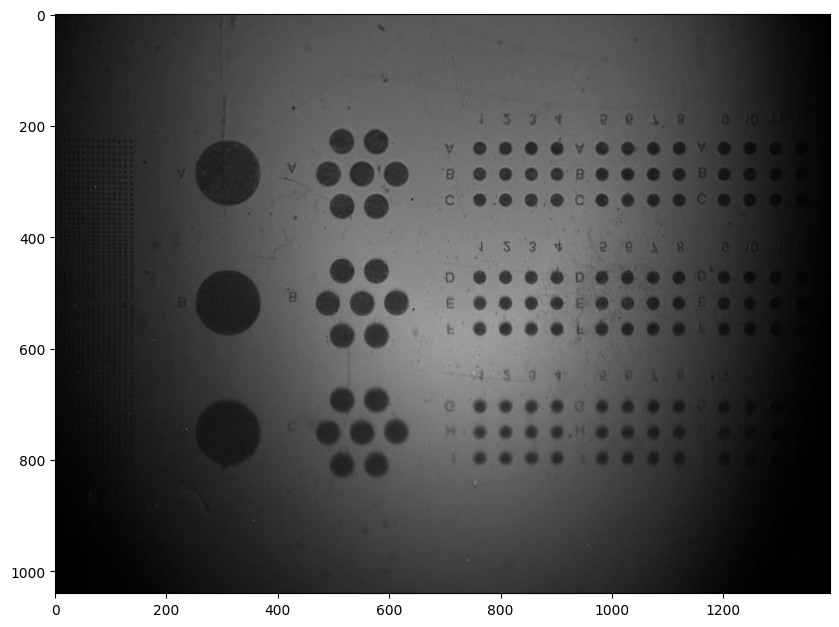

[generate_masks] executed in 7.8670 seconds
[filter_masks] executed in 1.7846 seconds
Translation: [20.30944823 53.15378214]
Scale: 1.005253050609981
Rotation: -0.6723637157259361°


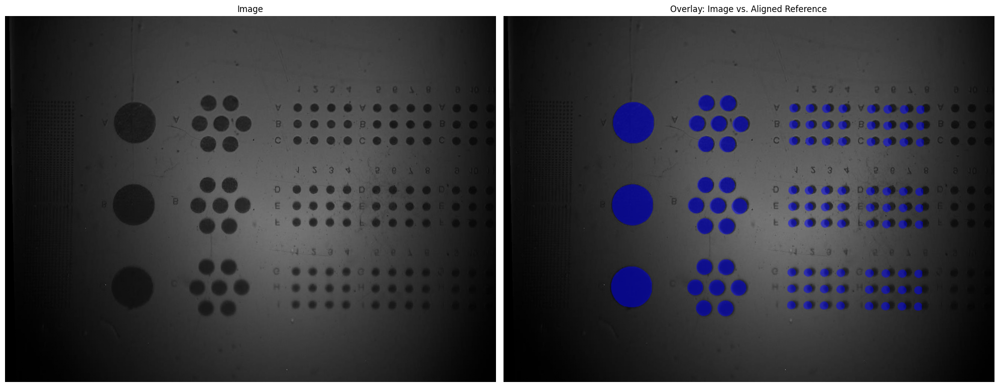

Average IoU all: 0.3377914880295653
Average IoU large: 0.9076278442826076
Average IoU medium: 0.7614330469067772
Average IoU small: 0.1904861851798351
[evaluate_camera_calibration] executed in 20.8593 seconds
[generate_masks] executed in 8.1308 seconds
[filter_masks] executed in 2.0452 seconds
Translation: [-1.32388222 -4.66395162]
Scale: 0.9987837362570915
Rotation: -0.030899376992437055°


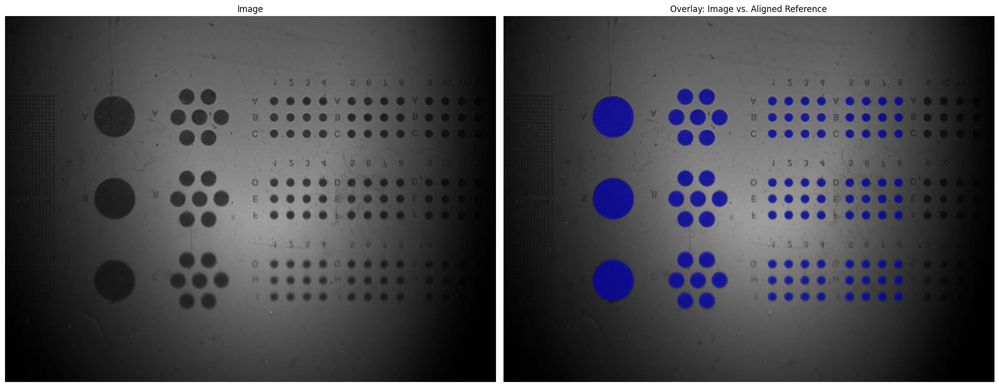

Average IoU all: 0.7921626742841824
Average IoU large: 0.9293317946081682
Average IoU medium: 0.8861371590685491
Average IoU small: 0.75903806954191
[evaluate_camera_calibration] executed in 19.4481 seconds
==== Evaluating camera calibration for image 290-4-0,75x-5,2_-1. ====
[generate_masks] executed in 7.9952 seconds
[filter_masks] executed in 2.3389 seconds
Translation: [21.2627172  45.07522073]
Scale: 1.0043072976724847
Rotation: -0.6345883581531382°


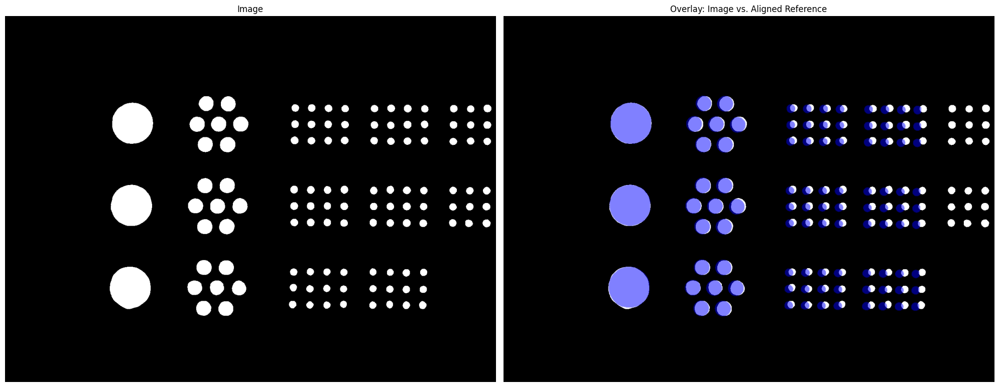

[_apply_imreg_dft] executed in 6.2585 seconds
[generate_masks] executed in 7.9855 seconds
[filter_masks] executed in 2.2657 seconds
Src: 96, Dst: 96


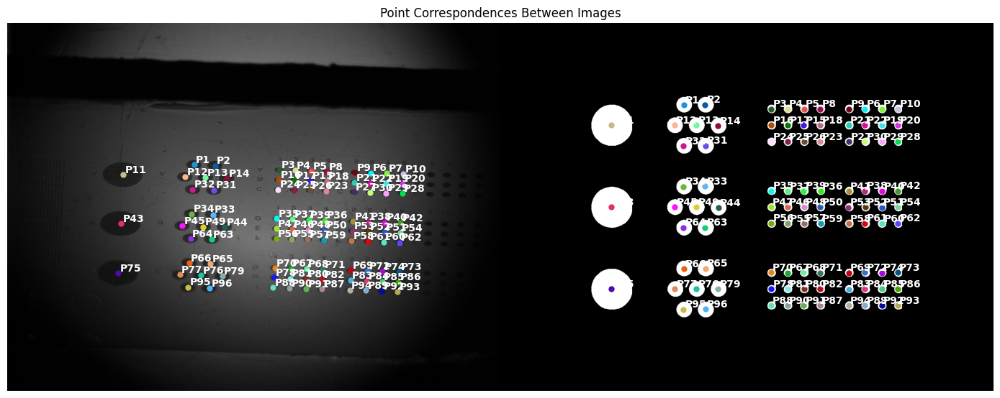

[calculate_homography] executed in 27.8932 seconds
[undistort] executed in 27.9014 seconds


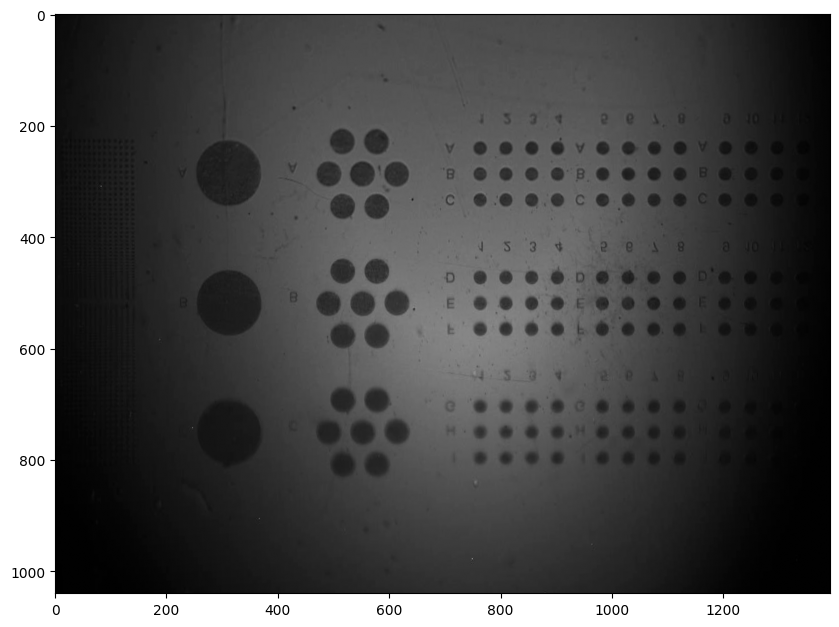

[generate_masks] executed in 7.9711 seconds
[filter_masks] executed in 2.2498 seconds
Translation: [21.2627172  45.07522073]
Scale: 1.0043072976724847
Rotation: -0.6345883581531382°


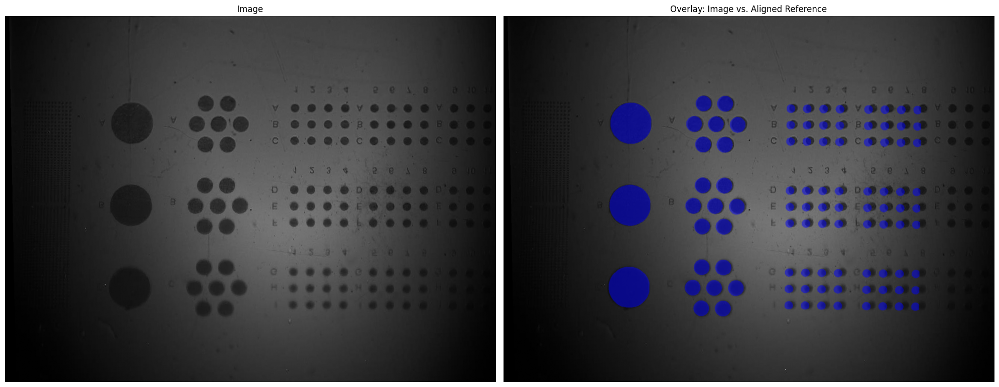

Average IoU all: 0.33865212892667484
Average IoU large: 0.8790683885165285
Average IoU medium: 0.773868993282836
Average IoU small: 0.1870915242752811
[evaluate_camera_calibration] executed in 19.2480 seconds
[generate_masks] executed in 7.9096 seconds
[filter_masks] executed in 2.1435 seconds
Translation: [-1.86154887 -3.64498876]
Scale: 0.9994733573165611
Rotation: -0.009879709693649374°


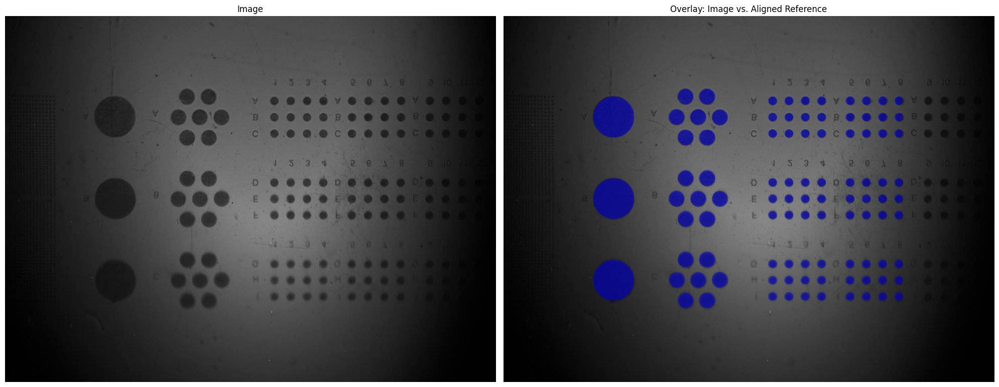

Average IoU all: 0.8356646513156399
Average IoU large: 0.8712558769103486
Average IoU medium: 0.8517073100553626
Average IoU small: 0.8295025747834415
[evaluate_camera_calibration] executed in 19.3790 seconds
==== Evaluating camera calibration for image 290-4-0,75x-6,5_-1. ====
[generate_masks] executed in 7.7854 seconds
[filter_masks] executed in 1.7957 seconds
Translation: [49.91946358 56.29295881]
Scale: 1.0033110206934652
Rotation: -0.3434965354504982°


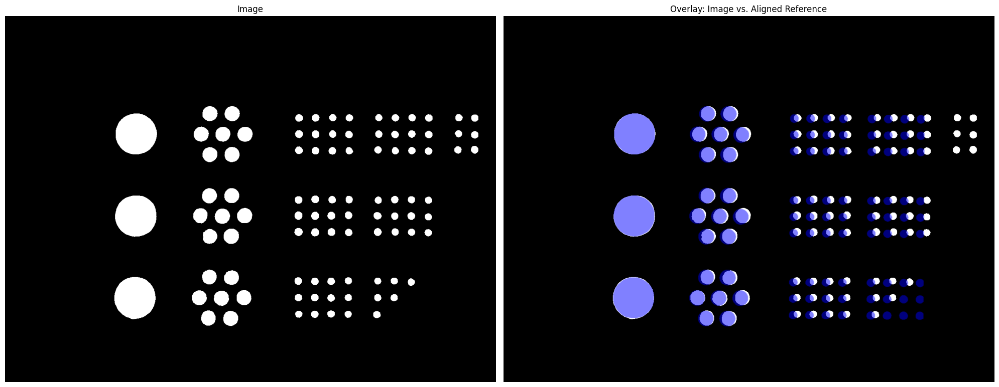

[_apply_imreg_dft] executed in 6.1914 seconds
[generate_masks] executed in 7.7335 seconds
[filter_masks] executed in 1.8050 seconds
Src: 90, Dst: 90


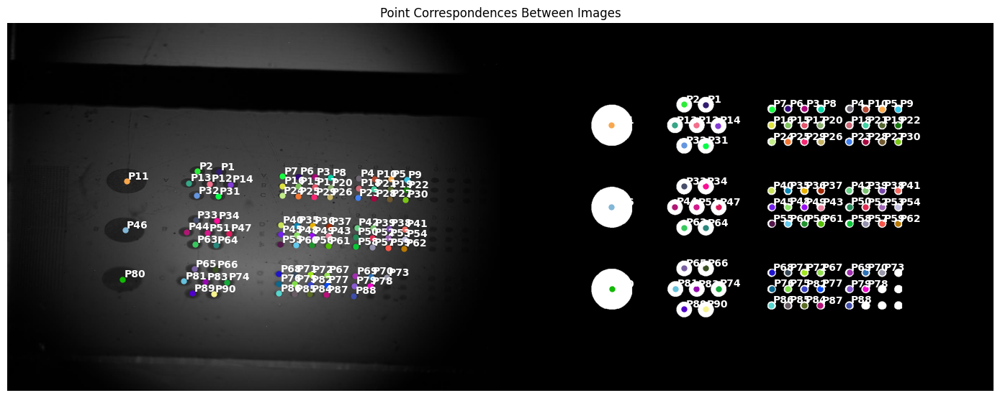

[calculate_homography] executed in 27.2533 seconds
[undistort] executed in 27.2743 seconds


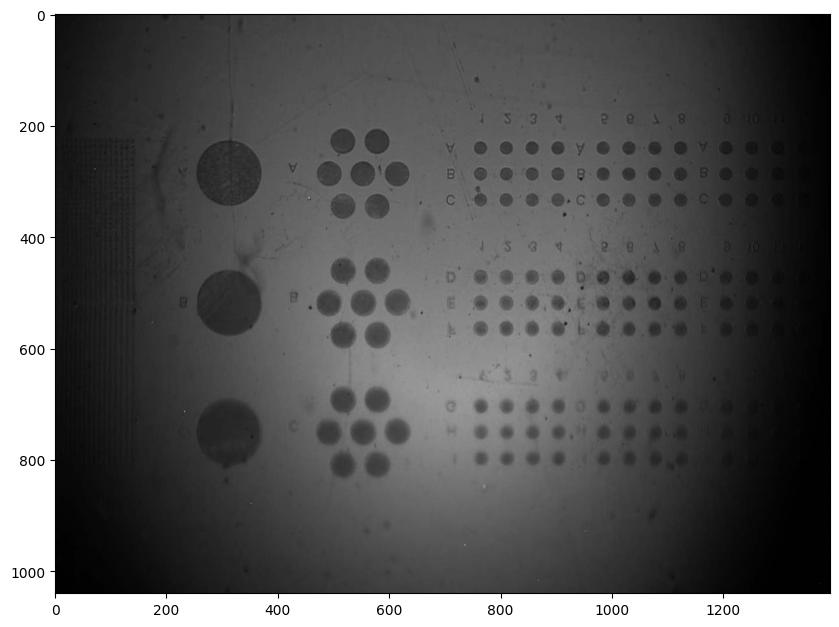

[generate_masks] executed in 7.9269 seconds
[filter_masks] executed in 1.7878 seconds
Translation: [49.91946358 56.29295881]
Scale: 1.0033110206934652
Rotation: -0.3434965354504982°


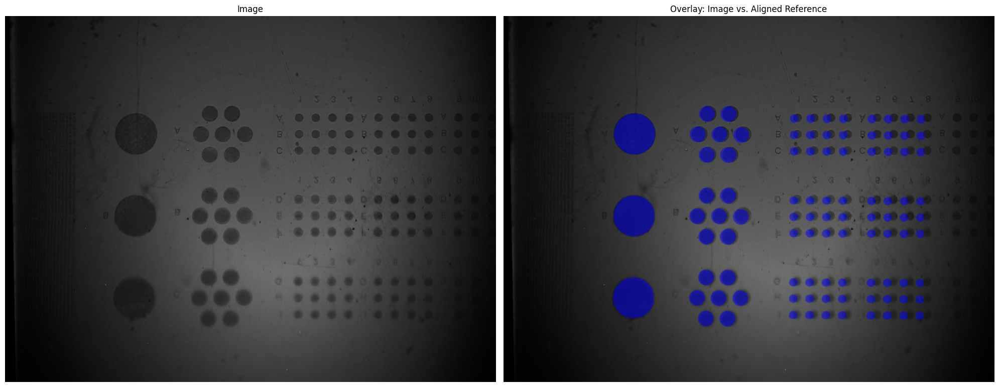

Average IoU all: 0.3119388778652777
Average IoU large: 0.8841267436883059
Average IoU medium: 0.7167489488026537
Average IoU small: 0.15228926712849683
[evaluate_camera_calibration] executed in 18.5982 seconds
[generate_masks] executed in 7.7885 seconds
[filter_masks] executed in 1.9763 seconds
Translation: [-1.83234988 -2.61989137]
Scale: 1.0004643053462658
Rotation: -0.007082296079090611°


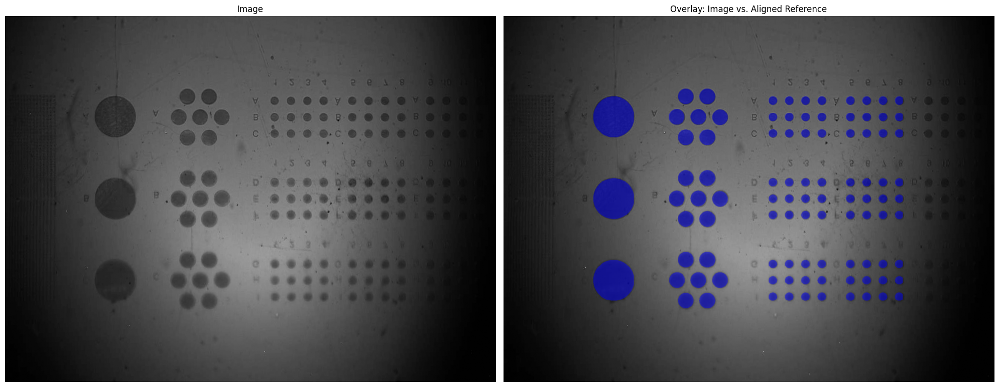

Average IoU all: 0.8209827917734629
Average IoU large: 0.9416448096604059
Average IoU medium: 0.8844541479697169
Average IoU small: 0.7960580192178431
[evaluate_camera_calibration] executed in 18.8733 seconds
==== Evaluating camera calibration for image 290-4-0,75x-10,4_-1. ====
[generate_masks] executed in 7.4900 seconds
[filter_masks] executed in 1.4061 seconds
Translation: [50.24313644 54.08965568]
Scale: 1.0026585307065914
Rotation: -0.4037699735016247°


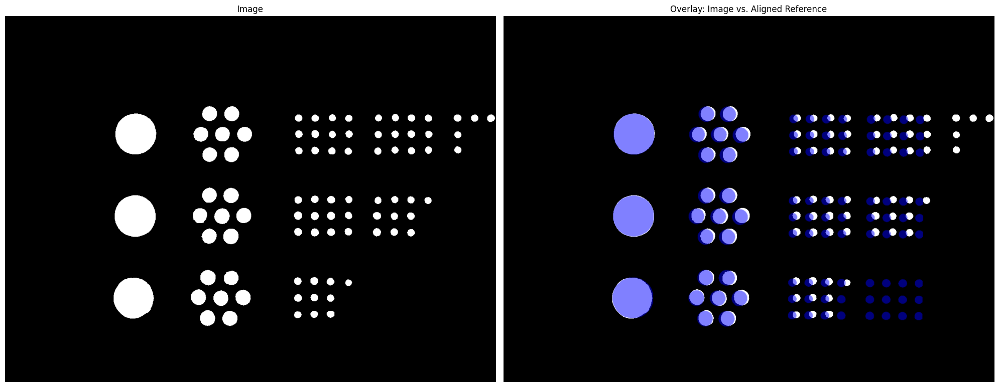

[_apply_imreg_dft] executed in 6.2090 seconds
[generate_masks] executed in 7.4895 seconds
[filter_masks] executed in 1.3905 seconds
Src: 80, Dst: 80


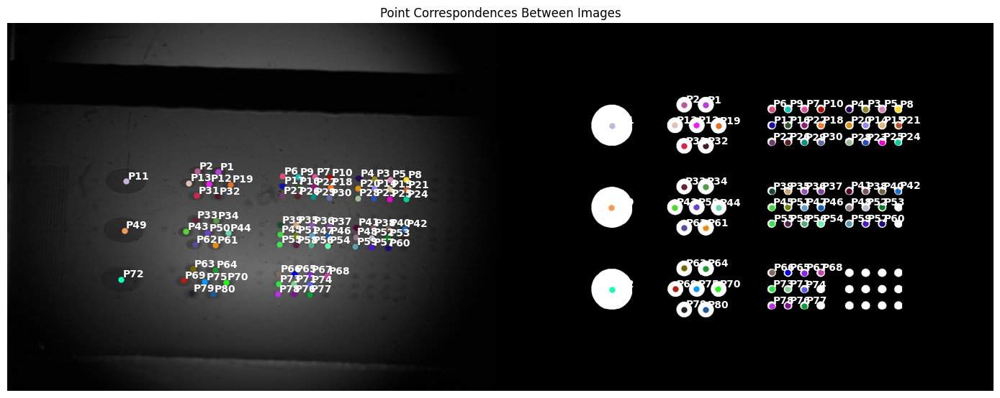

[calculate_homography] executed in 24.9290 seconds
[undistort] executed in 24.9373 seconds


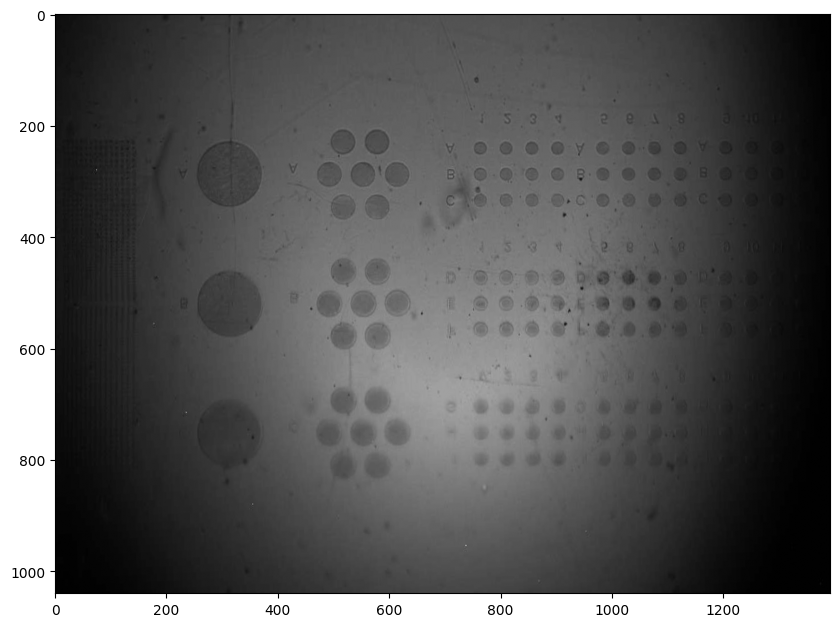

[generate_masks] executed in 7.5501 seconds
[filter_masks] executed in 1.3976 seconds
Translation: [50.24313644 54.08965568]
Scale: 1.0026585307065914
Rotation: -0.4037699735016247°


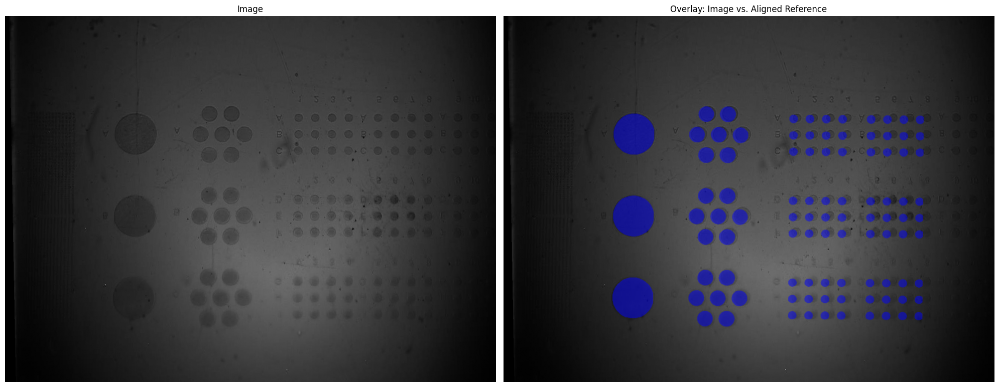

Average IoU all: 0.3241961341587663
Average IoU large: 0.9326624783983851
Average IoU medium: 0.6853414800729022
Average IoU small: 0.136007108220452
[evaluate_camera_calibration] executed in 17.3343 seconds
[generate_masks] executed in 7.5341 seconds
[filter_masks] executed in 1.2808 seconds
Translation: [-1.51815844 -1.30852607]
Scale: 1.000244893068517
Rotation: 0.043489538695212104°


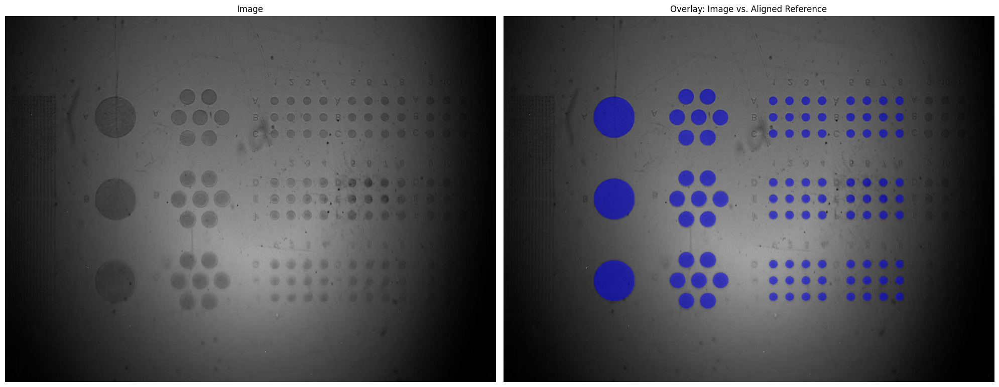

Average IoU all: 0.8249975581738707
Average IoU large: 0.9431652007812352
Average IoU medium: 0.8653859857848764
Average IoU small: 0.8035214883943488
[evaluate_camera_calibration] executed in 17.5200 seconds
==== Evaluating camera calibration for image 290-4-0,75x-14,7_-1. ====
[generate_masks] executed in 7.2885 seconds
[filter_masks] executed in 0.8495 seconds
Translation: [49.96156239 54.97438297]
Scale: 1.0034888500269061
Rotation: -0.5494665848237617°


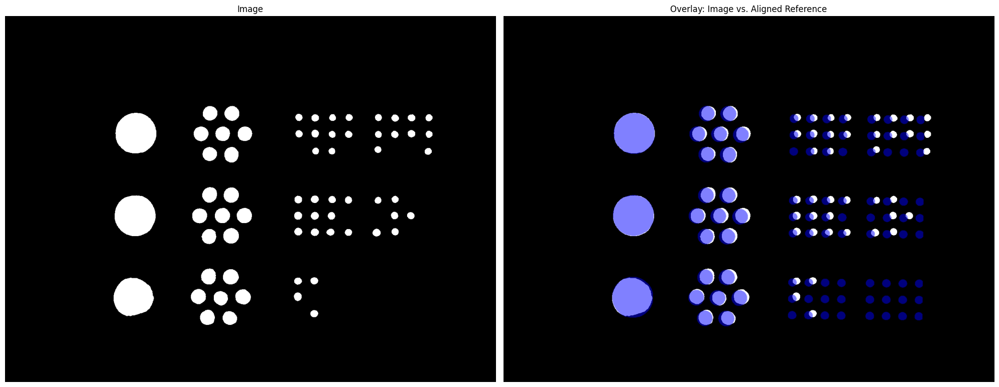

[_apply_imreg_dft] executed in 6.2621 seconds
[generate_masks] executed in 7.7212 seconds
[filter_masks] executed in 1.7635 seconds
Src: 65, Dst: 65


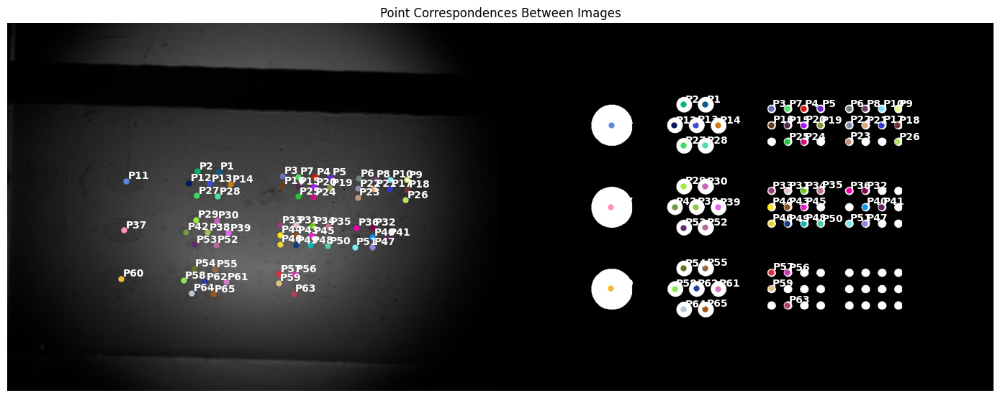

[calculate_homography] executed in 25.5340 seconds
[undistort] executed in 25.5426 seconds


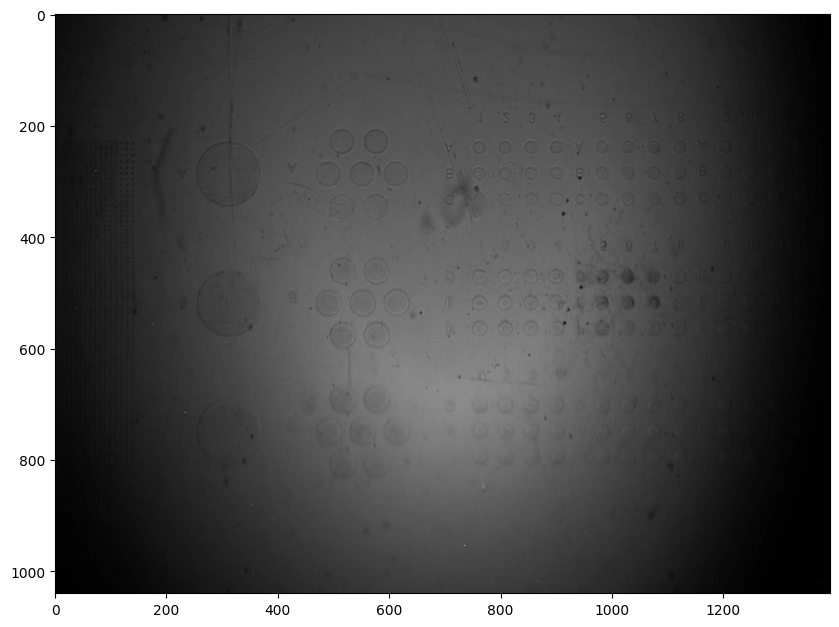

[generate_masks] executed in 7.3038 seconds
[filter_masks] executed in 0.8518 seconds
Translation: [49.96156239 54.97438297]
Scale: 1.0034888500269061
Rotation: -0.5494665848237617°


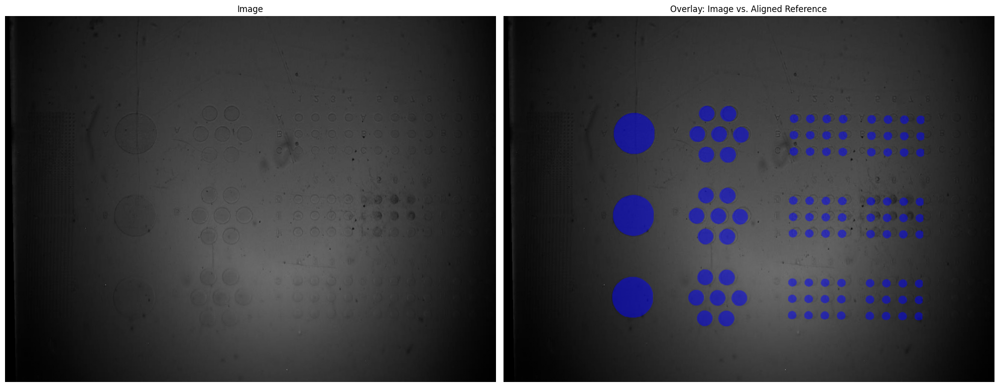

Average IoU all: 0.3574672037085243
Average IoU large: 0.9086956399709076
Average IoU medium: 0.6563108135058487
Average IoU small: 0.13720606163821977
[evaluate_camera_calibration] executed in 16.1611 seconds
[generate_masks] executed in 7.2389 seconds
[filter_masks] executed in 0.8520 seconds
Translation: [-1.20836317 -1.89676943]
Scale: 0.9993351423874459
Rotation: 0.044028640607905345°


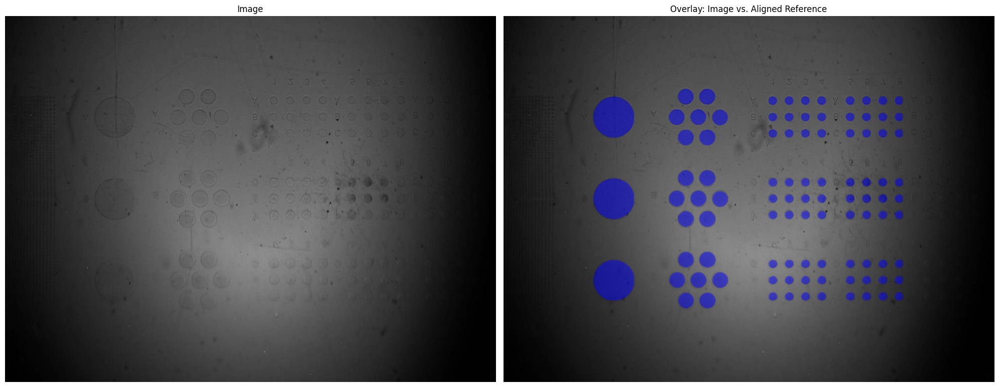

Average IoU all: 0.7976166098257299
Average IoU large: 0.9124176666465234
Average IoU medium: 0.8606854915483331
Average IoU small: 0.745465057118322
[evaluate_camera_calibration] executed in 16.1027 seconds
==== Evaluating camera calibration for image 290-4-0,75x-19_-1. ====
[generate_masks] executed in 7.1691 seconds
[filter_masks] executed in 0.5081 seconds
Translation: [48.25850569 55.57009649]
Scale: 1.0034278471992988
Rotation: -0.4571079459206544°


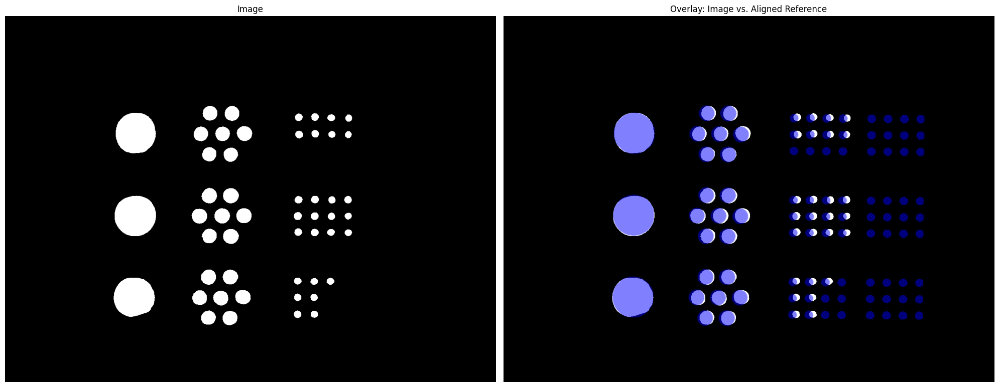

[_apply_imreg_dft] executed in 6.2416 seconds
[generate_masks] executed in 7.1028 seconds
[filter_masks] executed in 0.5710 seconds
Src: 51, Dst: 51


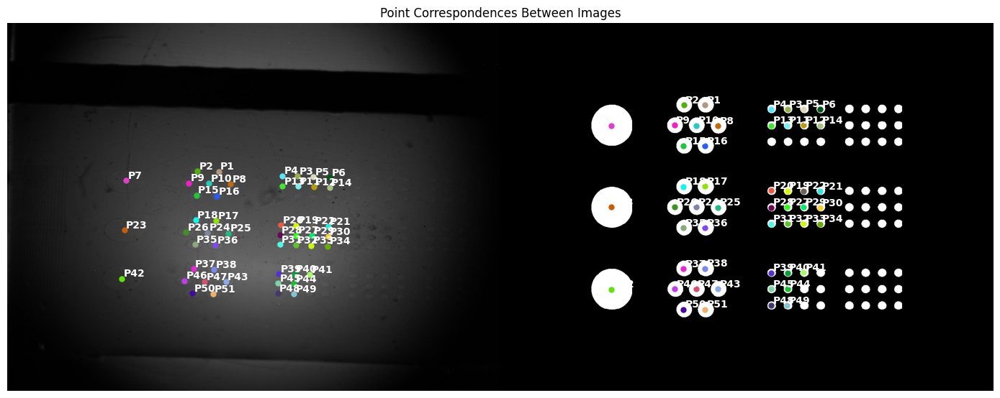

[calculate_homography] executed in 22.3590 seconds
[undistort] executed in 22.3673 seconds


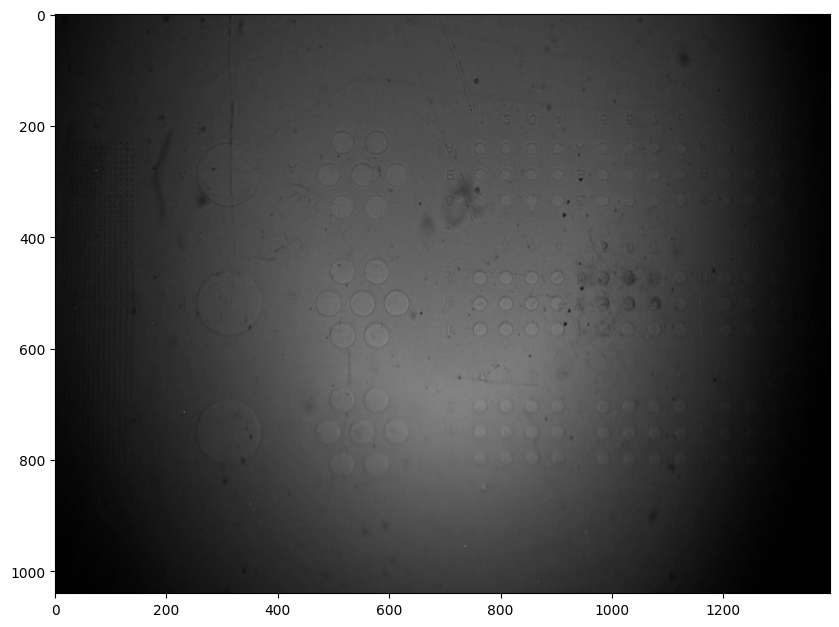

[generate_masks] executed in 7.1347 seconds
[filter_masks] executed in 0.4950 seconds
Translation: [48.25850569 55.57009649]
Scale: 1.0034278471992988
Rotation: -0.4571079459206544°


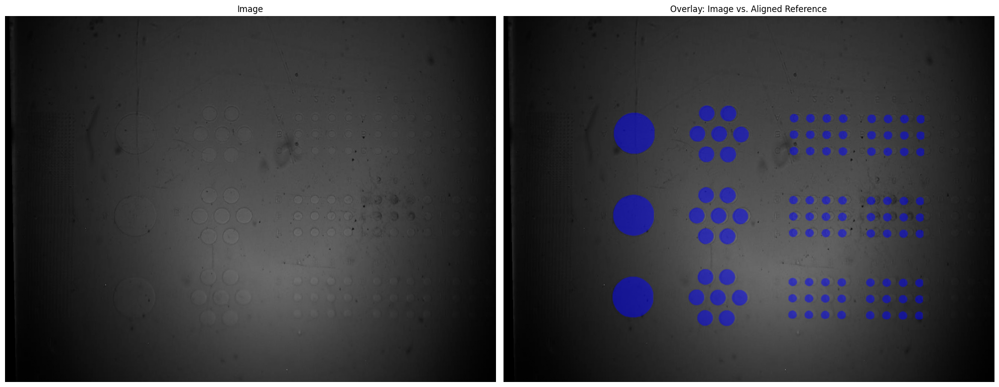

Average IoU all: 0.45760734773676975
Average IoU large: 0.885307883822228
Average IoU medium: 0.6971843287500485
Average IoU small: 0.22374741405027973
[evaluate_camera_calibration] executed in 15.4268 seconds
[generate_masks] executed in 7.1044 seconds
[filter_masks] executed in 0.5067 seconds
Translation: [-0.71187724 -3.99104138]
Scale: 0.9981460543514133
Rotation: -0.18262682033653732°


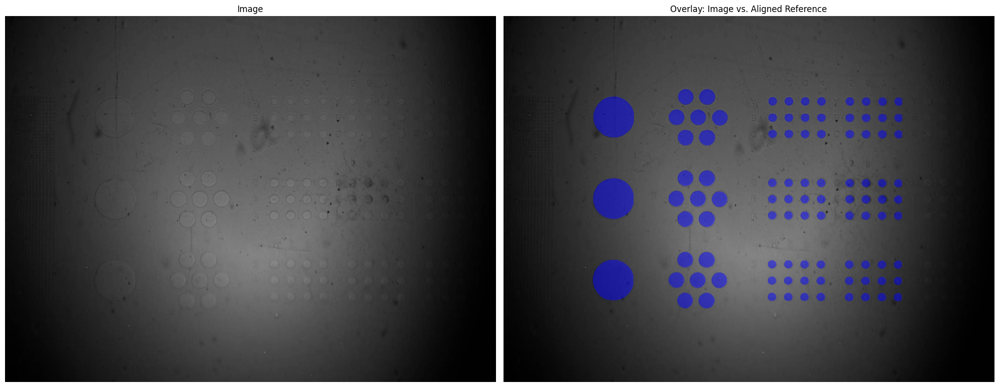

Average IoU all: 0.8247524685426385
Average IoU large: 0.936180062799497
Average IoU medium: 0.847822421625362
Average IoU small: 0.7944283278942024
[evaluate_camera_calibration] executed in 15.4450 seconds


In [4]:
df = pd.DataFrame(columns=["iou_all", "iou_large", "iou_medium", "iou_small"])

for image_data in tqdm(data):
    name = image_data["file_path"].split('/')[-1].split('.')[0]
    print(f"==== Evaluating camera calibration for image {name}. ====")
    
    # Open Image
    gray_image = np.array(Image.open(image_data["file_path"]).convert("L"))

    corrected, affine = calibrator.undistort(
        gray_image,
        chip_region=EXPERIMENT_CONFIG["chip_region"],
        debug=EXPERIMENT_CONFIG["debug"]
    )
    
    plt.figure(figsize=(10,10))
    plt.imshow(corrected, cmap='gray')
    plt.show()

    iou_all, iou_large, iou_medium, iou_small = evaluate_camera_calibration(
        image=affine, 
        ref_image=calibrator.ref_image, 
        segmenter=segmenter, 
        debug=EXPERIMENT_CONFIG["debug"]
    )
    df.loc[len(df)] = [iou_all, iou_large, iou_medium, iou_small]

    iou_all, iou_large, iou_medium, iou_small = evaluate_camera_calibration(
        image=corrected, 
        ref_image=calibrator.ref_image, 
        segmenter=segmenter, 
        debug=EXPERIMENT_CONFIG["debug"]
    )
    df.loc[len(df)] = [iou_all, iou_large, iou_medium, iou_small]


In [5]:
print(df)

     iou_all  iou_large  iou_medium  iou_small
0   0.367174   0.916916    0.801227   0.217669
1   0.842052   0.930054    0.865202   0.831633
2   0.317099   0.923480    0.742437   0.167777
3   0.835721   0.932932    0.884795   0.817358
4   0.343926   0.923985    0.759057   0.196632
5   0.833979   0.949818    0.905305   0.808349
6   0.337791   0.907628    0.761433   0.190486
7   0.792163   0.929332    0.886137   0.759038
8   0.338652   0.879068    0.773869   0.187092
9   0.835665   0.871256    0.851707   0.829503
10  0.311939   0.884127    0.716749   0.152289
11  0.820983   0.941645    0.884454   0.796058
12  0.324196   0.932662    0.685341   0.136007
13  0.824998   0.943165    0.865386   0.803521
14  0.357467   0.908696    0.656311   0.137206
15  0.797617   0.912418    0.860685   0.745465
16  0.457607   0.885308    0.697184   0.223747
17  0.824752   0.936180    0.847822   0.794428


In [6]:
import pandas as pd
import numpy as np

import pandas as pd

def save_df_with_even_odd_averages(df, filename='output.csv'):
    # Select even and odd rows by index
    even_rows = df.iloc[::2]   # rows 0, 2, 4, ...
    odd_rows = df.iloc[1::2]   # rows 1, 3, 5, ...

    # Compute averages (numeric columns only)
    even_avg = even_rows.mean(numeric_only=True)
    odd_avg = odd_rows.mean(numeric_only=True)

    # Label the rows
    even_avg.name = 'average_even_rows'
    odd_avg.name = 'average_odd_rows'

    # Print the averages
    print("Average of even-indexed rows:")
    print(even_avg)
    print("Average of odd-indexed rows:")
    print(odd_avg)

    # Append to DataFrame
    df_with_averages = pd.concat([df, even_avg.to_frame().T, odd_avg.to_frame().T], axis=0)

    # Save to CSV
    df_with_averages.to_csv(filename, index=True)

    return df_with_averages

result = save_df_with_even_odd_averages(df)

Average of even-indexed rows:
iou_all       0.350650
iou_large     0.906874
iou_medium    0.732623
iou_small     0.178767
Name: average_even_rows, dtype: float64
Average of odd-indexed rows:
iou_all       0.823103
iou_large     0.927422
iou_medium    0.872388
iou_small     0.798373
Name: average_odd_rows, dtype: float64
